<a href="https://colab.research.google.com/github/taehi5/Esaa_YB/blob/7%EC%A3%BC%EC%B0%A8-%EA%B3%BC%EC%A0%9C/ESAA_YB_Week7_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

` 파이썬 머신러닝 완벽가이드 ch4. 7, 8, 11 pg.244~267, 295~306`

# LightGBM





## 1. 정의

  1) XGBoost와의 비교
   - xgboost보다 학습 시간 및 메모리 사용량이 적음
   - xgboost와 예측 성능이 비슷하고 기능상의 다양성이 많음
   - 카테고리형 필터의 자동 변환과 최적 분할
   - 만건 이하의 데이터 세트에서 과적합의 가능성이 있음

  2) 사용 방법
  - 트리의 균형을 맞추지 않고 최대 손실 값을 가지는 리프 노드를 지속적으로 분학하며 트리의 깊이가 깊어지고 비대칭인 규칙 트리가 생성되는 **리프 중심 트리 분할** 사용
  - 균형 트리 방식보다 예측 오류 손실을 최소화할 수 있다.

  3) 파이썬 내에서의 사용
  - 패키지명 : lightgbm
  - 분류 : LGBMClassifier
  - 회귀: LGBMRegressor


## 2. LIGHTGBM 설치

In [3]:
pip install lightgbm==3.3.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 15.4 MB/s  0:00:00
  Attempting uninstall: lightgbm
    Found existing installation: lightgbm 4.6.0
    Uninstalling lightgbm-4.6.0:
      Successfully uninstalled lightgbm-4.6.0


In [4]:
import lightgbm
from lightgbm import LGBMClassifier

## 3. LIGHTGBM 하이퍼 파라미터
❗Xgboost와 다르게 리프 노드가 계속 분할되면서 트리의 깊이가 깊어져 이러한 트리 특성에 맞는 하이퍼 파라미터 설정이 필요

**주요 파라미터**
- num_iteration[ default = 100] :  반복 수행하는 트리 개수 지정
- learning_rate[default=0.1]: 부스팅 스텝을 반복적으로 수행할 때 업데이트되는 학습률 값
- max_depth[default = -1]: 트리 기반 max_depth와 동일
- min_data_in_leaf[default=-1]:리프 노드가 되기 위해 최소한으로 필요한 레코드 수

- num_leaves [default=3]: 하나의 트리가 가질 수 있는 최대 리프 개수
- boosting[default=gbdt]: 부스팅의 트리를 생성하는 알고리즘 기술,gbdt는 일반적인 그래디언트 부스팅 결정 트리, rf는 랜덤 포레스트
- bagging_fraction[default=1.0]: 트리가 커져서 과적합 되는 것을 제얼하기 위해 데이터를 샘플링하는 비율 지정
- feature_fraction[default=1.0]: 개별 트리를 학습할 때마다 무작위로 선택하는 피터의 비율
- lamda_l2[default=0.0]: l2 regulation 제어를 위한 값
- lamda_l1[default=0.0]: l1 regulation 제어를 위한 값

- learining task 파라미터: objective, 최솟값을 가져야 할 손실 함수 정의

## 4. 하이퍼 파라미터 튜닝 방안

기본: num_leaves의 개수를 중심으로 min_child_samples(min_data_in_leaf), max_depth를 함께 조정하면서 모델의 복잡도를 줄임
❗ 단, n_estimators가 너무 크면 과적합으로 성능이 저하될 수 있음.


- 규제 적용: reg_lambda, reg_alpha로 모델의 복잡도를 제어함.

- 샘플링 적용:
  - colsample_bytree: 트리 학습에 사용할 피처의 비율을 조절함.
  - subsample: 학습에 사용할 데이터의 비율을 조절함.

## 5. 파리썬 래퍼 LightGBM과 사이킷런 래퍼 XGBoost, LightGBM 하이퍼 파라미터 비교

- 사이킷런과 호환되는 클래스를 제공함.
  - 분류: LGBMClassifier
  - 회귀: LGBMRegressor
- 사이킷런 래퍼 LightGBM과 XGBoost는 하이퍼파라미터 이름이 대부분 같음.
- 파이썬 래퍼와 사이킷런 래퍼는 같은 기능도 파라미터 이름이 다를 수 있음.
  - num_iterations`→ n_estimators
  - min_data_in_leaf → min_child_samples
  - bagging_fraction → subsample
  - feature_fraction → colsample_bytree
  - lambda_l1, lambda_l2 → reg_alpha, reg_lambda

## 6. LightGBM 적용 - 위스콘신 유방암 예측
* XGBoost와 동일하게 early stopping 가능 , n_estimators = 400, early_stopping_rounds = 50 설정

In [5]:
!pip install scikit-learn==1.2.2 xgboost==1.7.6 lightgbm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 23.6 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> scikit-learn

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


In [9]:
# LightGBM의 LGBMClassifier 임포트
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

dataset = load_breast_cancer()

cancer_df = pd.DataFrame(data=dataset.data,columns=dataset.feature_names)

cancer_df["target"] = dataset.target
X_features = cancer_df.iloc[:, :-1]
y_label = cancer_df.iloc[:, -1]

# 전체 데이터의 80%는 학습용, 20%는 테스트용으로 분리
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_label, test_size=0.2, random_state=156
)

# 학습 데이터의 90%는 학습용, 10%는 검증용으로 분리
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=156
)

# 모델 생성
lgbm_wrapper = LGBMClassifier(
    n_estimators=400,
    learning_rate=0.05
)

evals = [(X_tr, y_tr), (X_val, y_val)]

# 카페 수정 사항: callbacks를 이용한 조기 중단
lgbm_wrapper.fit(X_tr,y_tr,callbacks=[early_stopping(stopping_rounds=50),
        log_evaluation(period=10)],eval_metric="logloss",eval_set=evals)

preds = lgbm_wrapper.predict(X_test)
pred_proba = lgbm_wrapper.predict_proba(X_test)[:, 1]

Training until validation scores don't improve for 50 rounds
[10]	training's binary_logloss: 0.386526	valid_1's binary_logloss: 0.461267
[20]	training's binary_logloss: 0.246443	valid_1's binary_logloss: 0.362062
[30]	training's binary_logloss: 0.167198	valid_1's binary_logloss: 0.310105
[40]	training's binary_logloss: 0.115054	valid_1's binary_logloss: 0.282853
[50]	training's binary_logloss: 0.0789991	valid_1's binary_logloss: 0.267587
[60]	training's binary_logloss: 0.0550801	valid_1's binary_logloss: 0.260746
[70]	training's binary_logloss: 0.0383095	valid_1's binary_logloss: 0.267484
[80]	training's binary_logloss: 0.0264668	valid_1's binary_logloss: 0.270523
[90]	training's binary_logloss: 0.0183664	valid_1's binary_logloss: 0.276485
[100]	training's binary_logloss: 0.0126961	valid_1's binary_logloss: 0.279265
[110]	training's binary_logloss: 0.00882581	valid_1's binary_logloss: 0.282152
Early stopping, best iteration is:
[61]	training's binary_logloss: 0.0532381	valid_1's binary

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

def get_clf_eval(y_test, pred, pred_proba):
    confusion = confusion_matrix(y_test, pred)
    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)

    # ROC-AUC 추가
    roc_auc = roc_auc_score(y_test, pred_proba)

    print("오차행렬")
    print(confusion)

    # ROC-AUC 출력 추가
    print(
        "정확도:{0:.4f}, 정밀도:{1:.4f}, 재현율:{2:.4f}, F1:{3:.4f}, AUC:{4:.4f}".format(
            accuracy, precision, recall, f1, roc_auc
        )
    )

In [11]:
get_clf_eval(y_test,preds,pred_proba)

오차행렬
[[34  3]
 [ 2 75]]
정확도:0.9561, 정밀도:0.9615, 재현율:0.9740, F1:0.9677, AUC:0.9877


피처 중요도를 시각화할 수 있는 내장 API 제공

<Axes: title={'center': 'Feature importance'}, xlabel='Feature importance', ylabel='Features'>

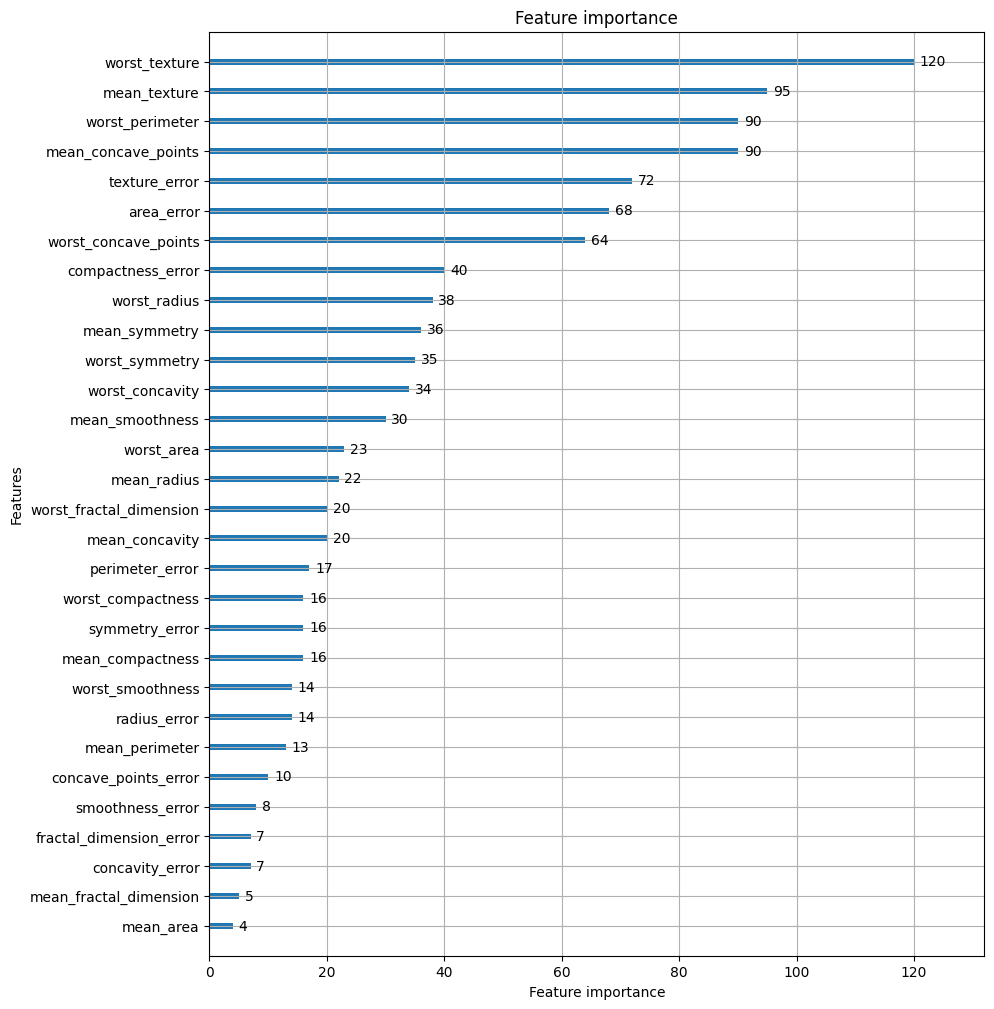

In [12]:
# plot_importance()를 이용하여 피처 중요도 시각화
from lightgbm import plot_importance
import matplotlib.pyplot as plt

%matplotlib inline

fig, ax = plt.subplots(figsize=(10, 12))
plot_importance(lgbm_wrapper, ax=ax)

# 베이지안 최적화 기반의 HyperOpt를 이용한 하이퍼 파라미터 튜닝

튜닝해야 할 하이퍼 파라미터 개수가 많으면 최적화 수행 시간이 오래걸림
➕ 개별 하이퍼 파라미터 값의 범위가 넓거나 학습 데이터가 대용량일 경우에는 최적화 시간이 늘어남

➡ 하이퍼 파라미터의 개수가 많음, 많은 시간 소모


In [13]:
params = {
    "max_depth": [10, 20, 30, 40, 50],
    "num_leaves": [35, 45, 55, 65],
    "colsample_bytree": [0.5, 0.6, 0.7, 0.8, 0.9],
    "subsample": [0.5, 0.6, 0.7, 0.8, 0.9],
    "min_child_weight": [10, 20, 30, 40],
    "reg_alpha": [0.01, 0.05, 0.1]
}

Grid Search를 적용할 경우 기하급수적으로 늘어나는 하이퍼 파라미터 최적화 시간 때문에 어쩔 수 없이 하이퍼 파라미터 개수를 줄이거나 개별 하이퍼 파라미터의 범위를 줄여야함.

▶ 실무에서는 다른 하이퍼 파라미터 튜닝이 적용됨

## 베이지안 최적화 개요

베이지안 최적화: 함수식을 알 수 없는 블랙박스 함수에서 최댓값 또는 최솟값을 만드는 입력값을 적은 시도로 효율적으로 찾는 기법

- 베이지안 확률: 새로운 사건의 관측이나 샘플 데이터를 기반으로 사후 확률을 개선해 나감.
- 베이지안 최적화는 새로운 관측 데이터를 바탕으로 대체 모델을 갱신하며 최적 입력값을 찾아감.
- 하이퍼파라미터 튜닝에서는 입력값이 하이퍼파라미터이고, 함수 반환값이 모델의 성능 평가 결과에 해당함.

✅ 2가지 중요 요소

- 대체 모델(Surrogate Model): 관측된 입력값과 성능 결과를 바탕으로 목적 함수를 추정하고, 예측값과 불확실성을 제공함.
- 획득 함수(Acquisition Function): 대체 모델의 예측값과 불확실성을 바탕으로 다음에 평가할 입력값을 결정함.

대체 모델은 새로운 관측 결과로 점차 개선되고, 획득 함수는 개선된 대체 모델을 기반으로 더 좋은 하이퍼파라미터 후보를 선택함.

**베이지안 최적화 수행 과정**

1. 초기 샘플링
   - 하이퍼파라미터를 랜덤하게 샘플링하여 모델을 학습하고 성능을 관측함.

2. 대체 모델 생성
   - 관측된 하이퍼파라미터와 성능 결과를 기반으로 목적 함수를 추정함.
   - 예측값과 함께 예측의 불확실성을 나타내는 신뢰 구간을 구함.
   - 지금까지 관측된 값 중 가장 좋은 성능을 최적 관측값으로 설정함.

3. 획득 함수로 다음 후보 선택
   - 대체 모델을 기반으로 기존 최적 관측값보다 더 좋은 결과를 얻을 가능성이 높은 하이퍼파라미터를 선택함.

4. 성능 관측 및 대체 모델 갱신
   - 선택한 하이퍼파라미터로 모델을 학습하고 성능을 관측함.
   - 새로운 관측 결과를 추가하여 대체 모델을 갱신함.

➡️ 3~4단계를 정해진 횟수만큼 반복하면서 예측의 불확실성을 줄이고 최적 입력값을 찾아감.

**대체 모델 알고리즘**

- 일반적으로 가우시안 프로세스를 사용함.
- HyperOpt는 TPE를 사용함.

## HyperOpt 사용하기

In [14]:
pip install hyperopt

**주요 로직**
- 첫째는 입력 변수명과 입력값의 검색 공간 설정
- 둘째는 목적 함수의 설정
- 마지막으로 목적 함수의 반환 최솟값을 가지는 최적 입력값을 유추하는 것  


**HyperOpt 검색 공간 설정**

- HyperOpt는 목적 함수의 반환값을 최소화하는 최적 입력값을 찾음.
- hp 모듈을 이용해 입력 변수와 검색 공간을 설정함.
- 검색 공간은 파이썬 딕셔너리로 정의함.
  - key: 입력 변수명
  - value: 해당 변수의 검색 공간
- label은 입력 변수의 이름, low와 high는 검색 범위의 최솟값과 최댓값, q는 간격을 의미함.
- 검색 공간의 값은 순서대로 선택되는 것이 아니라 샘플링됨.



In [15]:
from hyperopt import hp

# x: -10부터 10까지 1 간격, y: -15부터 15까지 1 간격
search_space = {
    "x": hp.quniform("x", -10, 10, 1),
    "y": hp.quniform("y", -15, 15, 1)
}

**HyperOpt 목적 함수 생성**

- 목적 함수는 입력 변수의 값이 담긴 딕셔너리를 인자로 받아 계산 결과를 반환하도록 작성함.
- 반환 형식은 숫자 또는 딕셔너리를 사용할 수 있음.
- 딕셔너리로 반환할 때는 다음 키를 설정해야 함.
  - loss: 최소화할 목적 함수의 계산 결과
  - status: 실행 상태로, 정상 수행 시 `STATUS_OK` 지정


In [16]:
from hyperopt import STATUS_OK

# 딕셔너리를 인자로 받아 목적 함수의 계산 결과를 반환
def objective_func(search_space):
    x = search_space["x"]
    y = search_space["y"]
    retval = x**2 - 20*y

    return retval

**최적 입력 변숫값 찾기**

fmin()은 지정한 검색 공간에서 목적 함수의 반환값을 최소화하는 입력값을 찾음.

✅ 주요 인자

- fn: 최적화할 목적 함수
- space: 입력 변수의 검색 공간을 정의한 딕셔너리
- algo: 최적화 알고리즘으로,
- max_evals: 목적 함수를 평가할 총횟수
- trials: 시도한 입력값과 목적 함수의 반환 결과를 저장하는 Trials객체
- rstate: 결과 재현을 위한 난수 생성기
  - HyperOpt 버전에 따라 설정 방식이나 실행 결과가 달라질 수 있음.



In [17]:
from hyperopt import fmin, tpe, Trials

# 탐색 결과를 저장할 Trials 객체 생성
trial_val = Trials()

# 5회 탐색
best_01 = fmin(fn=objective_func,space=search_space,algo=tpe.suggest, max_evals=5, trials=trial_val,rstate=np.random.default_rng(seed=0))
print("best:", best_01)

100%|██████████| 5/5 [00:00<00:00, 499.17trial/s, best loss: -224.0]
best: {'x': np.float64(-4.0), 'y': np.float64(12.0)}


In [18]:
trial_val = Trials()

# max_evals를 20으로 늘려서 재탐색
best_02 = fmin(
    fn=objective_func,
    space=search_space,
    algo=tpe.suggest,
    max_evals=20,
    trials=trial_val,
    rstate=np.random.default_rng(seed=0)
)

print("best:", best_02)

100%|██████████| 20/20 [00:00<00:00, 688.11trial/s, best loss: -296.0]
best: {'x': np.float64(2.0), 'y': np.float64(15.0)}


➡️ 탐색 횟수를 늘리면 더 좋은 입력값을 찾을 기회가 늘어나지만, 항상 정확한 최적값을 찾는 것은 아님.

**Trials 객체의 주요 속성**

- Trials 객체는 목적 함수를 반복 실행할 때 사용한 입력값과 실행 결과를 저장함.
- results: 각 시도의 목적 함수 반환값과 실행 상태를 저장함.
- vals: 각 시도에 사용된 입력 변수의 값을 저장함.

✅ results 구조

- 리스트 안에 각 시도의 결과가 딕셔너리로 저장됨.
- loss: 목적 함수의 반환값
- status: 실행 상태로, 정상 수행 시 "ok"

In [19]:
# 각 시도의 목적 함수 반환값과 실행 상태 확인
print(trial_val.results)

[{'loss': -64.0, 'status': 'ok'}, {'loss': -184.0, 'status': 'ok'}, {'loss': 56.0, 'status': 'ok'}, {'loss': -224.0, 'status': 'ok'}, {'loss': 61.0, 'status': 'ok'}, {'loss': -296.0, 'status': 'ok'}, {'loss': -40.0, 'status': 'ok'}, {'loss': 281.0, 'status': 'ok'}, {'loss': 64.0, 'status': 'ok'}, {'loss': 100.0, 'status': 'ok'}, {'loss': 60.0, 'status': 'ok'}, {'loss': -39.0, 'status': 'ok'}, {'loss': 1.0, 'status': 'ok'}, {'loss': -164.0, 'status': 'ok'}, {'loss': 21.0, 'status': 'ok'}, {'loss': -56.0, 'status': 'ok'}, {'loss': 284.0, 'status': 'ok'}, {'loss': 176.0, 'status': 'ok'}, {'loss': -171.0, 'status': 'ok'}, {'loss': 0.0, 'status': 'ok'}]


**Trials의 vals 속성과 결과 정리**

- vals는 각 시도에 사용된 입력값을 딕셔너리로 저장함.
  - key: 입력 변수명
  - value: 각 시도에서 사용된 입력값의 리스트
- vals와 results를 함께 사용하면 입력값에 따른 목적 함수의 결과를 확인할 수 있음.


In [20]:
# 각 시도에서 사용된 입력값 확인
print(trial_val.vals)

{'x': [np.float64(-6.0), np.float64(-4.0), np.float64(4.0), np.float64(-4.0), np.float64(9.0), np.float64(2.0), np.float64(10.0), np.float64(-9.0), np.float64(-8.0), np.float64(-0.0), np.float64(-0.0), np.float64(1.0), np.float64(9.0), np.float64(6.0), np.float64(9.0), np.float64(2.0), np.float64(-2.0), np.float64(-4.0), np.float64(7.0), np.float64(-0.0)], 'y': [np.float64(5.0), np.float64(10.0), np.float64(-2.0), np.float64(12.0), np.float64(1.0), np.float64(15.0), np.float64(7.0), np.float64(-10.0), np.float64(0.0), np.float64(-5.0), np.float64(-3.0), np.float64(2.0), np.float64(4.0), np.float64(10.0), np.float64(3.0), np.float64(3.0), np.float64(-14.0), np.float64(-8.0), np.float64(11.0), np.float64(-0.0)]}


✅ DataFrame으로 정리
- 각 행은 한 번의 탐색에 해당하며, 입력값과 결과를 함께 비교할 수 있음.

In [21]:
import pandas as pd

# results에서 loss 값을 추출하여 리스트 생성
losses = [loss_dict["loss"] for loss_dict in trial_val.results]

# 입력값과 목적 함수 반환값을 DataFrame으로 생성
result_df = pd.DataFrame({
    "x": trial_val.vals["x"],
    "y": trial_val.vals["y"],
    "losses": losses
})

result_df

,x,y,losses
0,-6.0,5.0,-64.0
1,-4.0,10.0,-184.0
2,4.0,-2.0,56.0
3,-4.0,12.0,-224.0
4,9.0,1.0,61.0
5,2.0,15.0,-296.0
6,10.0,7.0,-40.0
7,-9.0,-10.0,281.0
8,-8.0,0.0,64.0
9,-0.0,-5.0,100.0


## HyperOpt를 이용한 XGBoost 하이퍼파라미터 최적화

- 최적화할 하이퍼파라미터와 검색 공간을 설정함.
- 목적 함수에서 XGBoost를 학습하고 예측 성능 평가 결과를 반환함.
- fmin()으로 검색 공간의 입력값을 탐색하여 최적의 예측 성능을 만드는 하이퍼파라미터 조합을 찾음.

❗ 주의 사항

- 정숫값만 받는 하이퍼파라미터는 입력 시 int()로 변환해야 함.
- HyperOpt는 목적 함수의 반환값을 최소화함.
  - 정확도, ROC-AUC처럼 높을수록 좋은 성능 지표는 -1을 곱해 반환해야 함.

In [22]:
# 전체 데이터의 80%는 학습용, 20%는 테스트용으로 분리
X_train, X_test, y_train, y_test = train_test_split(
    X_features, y_label, test_size=0.2, random_state=156
)

# 학습 데이터를 다시 학습용과 검증용으로 분리
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=156
)

In [23]:
from hyperopt import hp

# max_depth: 5~20, min_child_weight: 1~2, 각각 1 간격
# colsample_bytree: 0.5~1, learning_rate: 0.01~0.2의 균등 분포
xgb_search_space = {
    "max_depth": hp.quniform("max_depth", 5, 20, 1),
    "min_child_weight": hp.quniform("min_child_weight", 1, 2, 1),
    "learning_rate": hp.uniform("learning_rate", 0.01, 0.2),
    "colsample_bytree": hp.uniform("colsample_bytree", 0.5, 1)
}

**목적 함수 설정**
: 검색 공간에서 설정한 하이퍼 파라미터들을 입력받아서 XGBoost를 학습하고 평가지표를 반환할 수 있도록 구성

❗ 유의사항
- 정수형으로 형변환해야함
- 값이 클수록 좋은 성능 지표면 -1곱해서 반환


In [24]:
from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier
from hyperopt import STATUS_OK

# 정수형 하이퍼파라미터는 int()로 변환
# 정확도는 높을수록 좋으므로 -1을 곱해 최소화하도록 설정
def objective_func(search_space):
    # 수행 시간 절약을 위해 n_estimators=100으로 설정
    xgb_clf = XGBClassifier(n_estimators=100,max_depth=int(search_space["max_depth"]),min_child_weight=int(search_space["min_child_weight"]),    learning_rate=search_space["learning_rate"],colsample_bytree=search_space["colsample_bytree"],eval_metric="logloss")

    accuracy = cross_val_score(xgb_clf,X_train,y_train,scoring="accuracy",cv=3)

    # 3개 폴드의 정확도 평균에 -1을 곱해 반환
    return {"loss": -1 * np.mean(accuracy),"status": STATUS_OK}

fmin을 이용해 최적 하이퍼 파라미터 도출


In [26]:
from hyperopt import fmin, tpe, Trials

trial_val = Trials()

best = fmin(fn=objective_func,space=xgb_search_space,algo=tpe.suggest, max_evals=50,  # 최대 반복 횟수
    trials=trial_val,rstate=np.random.default_rng(seed=9))

print("best:", best)

100%|██████████| 50/50 [00:13<00:00,  3.72trial/s, best loss: -0.9714476588823051]
best: {'colsample_bytree': np.float64(0.5041680558682833), 'learning_rate': np.float64(0.13493661826434478), 'max_depth': np.float64(18.0), 'min_child_weight': np.float64(2.0)}


정수형 파라미터는 정수형으로 형 변환, 실수형 파라미터는 소수점 5자리까지만 변환

In [27]:
print("colsample_bytree:{0}, learning_rate:{1}, max_depth:{2}, min_child_weight:{3}".format(round(best["colsample_bytree"], 5),round(best["learning_rate"], 5),int(best["max_depth"]),int(best["min_child_weight"]))
)

colsample_bytree:0.50417, learning_rate:0.13494, max_depth:18, min_child_weight:2


In [29]:
xgb_wrapper = XGBClassifier(n_estimators=400,learning_rate=round(best["learning_rate"], 5),max_depth=int(best["max_depth"]), min_child_weight=int(best["min_child_weight"]), colsample_bytree=round(best["colsample_bytree"], 5),early_stopping_rounds=50, eval_metric="logloss")

evals = [(X_tr, y_tr), (X_val, y_val)]

xgb_wrapper.fit(X_tr, y_tr,eval_set=evals,verbose=True)

preds = xgb_wrapper.predict(X_test)
pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]

get_clf_eval(y_test, preds, pred_proba)

[0]	validation_0-logloss:0.56084	validation_1-logloss:0.57845
[1]	validation_0-logloss:0.48008	validation_1-logloss:0.51915
[2]	validation_0-logloss:0.41538	validation_1-logloss:0.47155
[3]	validation_0-logloss:0.36378	validation_1-logloss:0.43536
[4]	validation_0-logloss:0.31836	validation_1-logloss:0.40463
[5]	validation_0-logloss:0.28115	validation_1-logloss:0.38355
[6]	validation_0-logloss:0.24955	validation_1-logloss:0.36422
[7]	validation_0-logloss:0.22336	validation_1-logloss:0.34979
[8]	validation_0-logloss:0.20006	validation_1-logloss:0.33591
[9]	validation_0-logloss:0.18086	validation_1-logloss:0.32508
[10]	validation_0-logloss:0.16536	validation_1-logloss:0.31240
[11]	validation_0-logloss:0.15137	validation_1-logloss:0.30903
[12]	validation_0-logloss:0.13863	validation_1-logloss:0.30274
[13]	validation_0-logloss:0.12744	validation_1-logloss:0.29597
[14]	validation_0-logloss:0.11801	validation_1-logloss:0.29526
[15]	validation_0-logloss:0.10979	validation_1-logloss:0.29458
[1

# 스태킹 앙상블

스태킹(Stacking): 여러 개별 모델의 예측 결과를 새로운 학습 데이터로 사용하여 최종 모델이 다시 예측하는 앙상블 기법

✅ 모델 구성
- 기반 모델: 원본 데이터를 학습하고 예측 결과를 생성하는 개별 모델
- 최종 메타 모델: 기반 모델의 예측 결과를 피처로 사용하여 학습하고 최종 예측을 수행하는 모델

✅ 핵심 원리

- 여러 기반 모델의 예측 결과를 결합하여 메타 모델의 학습용·테스트용 피처 데이터 세트를 만듦.
- 개별 모델의 예측 결과를 기반으로 다시 학습하고 예측하는 방식을 메타 러닝이라고 함.

✅수행 과정
1. 여러 기반 모델을 각각 학습시킴.
2. 각 기반 모델의 예측 결과를 생성함.
3. 예측 결과를 칼럼 방향으로 결합하여 새로운 피처 데이터 세트를 만듦.
4. 결합된 피처와 정답값으로 메타 모델을 학습시킴.
5. 테스트 데이터에 대한 기반 모델의 예측 결과도 같은 방식으로 결합하여 최종 예측을 수행함.

✅ 데이터 형태 예시

- 원본 데이터: M개 행 × N개 피처
- 기반 모델 3개의 개별 예측 결과: 각각 M개 행 × 1개 칼럼
- 예측 결과를 결합한 메타 모델 입력: M개 행 × 3개 피처
- 메타 모델의 최종 예측 결과: M개 행 × 1개 칼럼

✅ 활용 및 특징

- 일반적으로 성능이 비슷한 모델을 결합해 추가적인 성능 향상을 얻고자 사용함.
- 캐글처럼 작은 성능 차이가 중요한 대회에서 자주 활용됨.
- 스태킹을 적용한다고 반드시 성능이 향상되는 것은 아님.
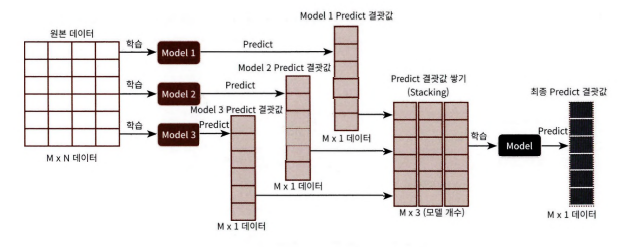

## 기본 스태킹 모델

In [30]:
import numpy as np

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

cancer_data = load_breast_cancer()

X_data = cancer_data.data
y_label = cancer_data.target

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_label, test_size=0.2, random_state=0
)

In [31]:
# 개별 ML 모델 생성
knn_clf = KNeighborsClassifier(n_neighbors=4)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=0)
dt_clf = DecisionTreeClassifier()
ada_clf = AdaBoostClassifier(n_estimators=100)

# 스태킹으로 생성한 데이터를 학습하고 예측할 최종 모델
lr_final = LogisticRegression()

In [32]:
# 개별 모델 학습
knn_clf.fit(X_train, y_train)
rf_clf.fit(X_train, y_train)
dt_clf.fit(X_train, y_train)
ada_clf.fit(X_train, y_train)

AdaBoostClassifier(n_estimators=100)

In [33]:
# 개별 모델의 예측 데이터 생성 및 정확도 측정
knn_pred = knn_clf.predict(X_test)
rf_pred = rf_clf.predict(X_test)
dt_pred = dt_clf.predict(X_test)
ada_pred = ada_clf.predict(X_test)

print("KNN 정확도: {0:.4f}".format(accuracy_score(y_test, knn_pred)))
print("랜덤 포레스트 정확도: {0:.4f}".format(accuracy_score(y_test, rf_pred)))
print("결정 트리 정확도: {0:.4f}".format(accuracy_score(y_test, dt_pred)))
print("에이다부스트 정확도: {0:.4f}".format(accuracy_score(y_test, ada_pred)))

KNN 정확도: 0.9211
랜덤 포레스트 정확도: 0.9649
결정 트리 정확도: 0.9123
에이다부스트 정확도: 0.9737


In [34]:
pred = np.array([knn_pred, rf_pred, dt_pred, ada_pred])
print(pred.shape)

# 행과 열을 교환하여 각 모델의 예측 결과를 피처로 구성
pred = np.transpose(pred)
print(pred.shape)

(4, 114)
(114, 4)


In [35]:
lr_final.fit(pred, y_test)
final = lr_final.predict(pred)

print(
    "최종 메타 모델의 예측 정확도: {0:.4f}".format(
        accuracy_score(y_test, final)
    )
)

최종 메타 모델의 예측 정확도: 0.9737


스태킹 후에 정확도가 향상됨.

## CV 세트 기반의 스태킹

과적합을 개선하기 위해 교차 검증으로 얻은 예측 결과를 최종 메타 모델의 학습 데이터로 사용하는 방식
- CV 기반 스태킹은 원본 학습 데이터에서 메타 모델의 학습 데이터를 생성하고, 테스트 데이터는 최종 평가에 사용함.

✅ 수행 과정

1. 각 기반 모델에서 메타 모델용 데이터 생성

학습 데이터를 K개의 폴드로 나누고, 각 기반 모델에서 다음 과정을 반복함.

   1. K-1개 폴드로 기반 모델을 학습함.
   2. 남은 검증 폴드를 예측하고, 결과를 원래 행 위치에 저장함.
   3. 같은 모델로 원본 테스트 데이터를 예측하고 결과를 저장함.
   4. 검증 폴드를 바꿔 가며 K회 반복함.

 - 메타 모델용 학습 데이터
   - 각 검증 폴드의 예측 결과를 원래 행 순서대로 모아 생성함.
   - 각 행의 예측값은 해당 행을 학습에 사용하지 않은 모델이 생성함.
 - 메타 모델용 테스트 데이터
   - K번 생성한 테스트 예측값을 행별로 평균하여 생성함.

2. 예측 결과 결합 및 메타 모델 학습

    1. 각 기반 모델이 생성한 학습 예측값을 칼럼 방향으로 결합함.
    2. 각 기반 모델이 생성한 테스트 예측값도 같은 방식으로 결합함.
   3. 결합한 학습 피처와 원본 학습 데이터의 정답으로 메타 모델을 학습함.
   4. 결합한 테스트 피처로 최종 예측을 수행함.
   5. 원본 테스트 데이터의 정답과 비교하여 성능을 평가함.

✅ 데이터 형태

기반 모델이 4개라면 다음과 같이 구성됨.

- 메타 모델 학습 피처: 원본 학습 데이터 행 수 × 4
- 메타 모델 테스트 피처: 원본 테스트 데이터 행 수 × 4
- 각 칼럼은 하나의 기반 모델이 생성한 예측값에 해당함.

In [36]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

# 기반 모델에서 메타 모델용 학습 및 테스트 데이터를 생성하는 함수
def get_stacking_base_datasets(model, X_train_n, y_train_n, X_test_n, n_folds):
    kf = KFold(n_splits=n_folds, shuffle=False)

    # 메타 모델용 예측 데이터를 저장할 배열 초기화
    train_fold_pred = np.zeros((X_train_n.shape[0], 1))
    test_pred = np.zeros((X_test_n.shape[0], n_folds))

    print(model.__class__.__name__, "model 시작")

    for folder_counter, (train_index, valid_index) in enumerate(kf.split(X_train_n)):
        print("\t 폴드 세트:", folder_counter, "시작")

        X_tr = X_train_n[train_index]
        y_tr = y_train_n[train_index]
        X_te = X_train_n[valid_index]

        # 학습 폴드로 기반 모델 학습
        model.fit(X_tr, y_tr)

        # 검증 폴드의 예측값을 원래 행 위치에 저장
        train_fold_pred[valid_index, :] = model.predict(X_te).reshape(-1, 1)

        # 원본 테스트 데이터의 예측값을 폴드별로 저장
        test_pred[:, folder_counter] = model.predict(X_test_n)

    # 폴드별 테스트 예측값을 평균하여 테스트 데이터 생성
    test_pred_mean = np.mean(test_pred, axis=1).reshape(-1, 1)

    return train_fold_pred, test_pred_mean

In [38]:
knn_train, knn_test = get_stacking_base_datasets( knn_clf, X_train, y_train, X_test, 7)

rf_train, rf_test = get_stacking_base_datasets(rf_clf, X_train, y_train, X_test, 7)

dt_train, dt_test = get_stacking_base_datasets( dt_clf, X_train, y_train, X_test, 7)

ada_train, ada_test = get_stacking_base_datasets(ada_clf, X_train, y_train, X_test, 7)

KNeighborsClassifier model 시작
	 폴드 세트: 0 시작
	 폴드 세트: 1 시작
	 폴드 세트: 2 시작
	 폴드 세트: 3 시작
	 폴드 세트: 4 시작
	 폴드 세트: 5 시작
	 폴드 세트: 6 시작
RandomForestClassifier model 시작
	 폴드 세트: 0 시작
	 폴드 세트: 1 시작
	 폴드 세트: 2 시작
	 폴드 세트: 3 시작
	 폴드 세트: 4 시작
	 폴드 세트: 5 시작
	 폴드 세트: 6 시작
DecisionTreeClassifier model 시작
	 폴드 세트: 0 시작
	 폴드 세트: 1 시작
	 폴드 세트: 2 시작
	 폴드 세트: 3 시작
	 폴드 세트: 4 시작
	 폴드 세트: 5 시작
	 폴드 세트: 6 시작
AdaBoostClassifier model 시작
	 폴드 세트: 0 시작
	 폴드 세트: 1 시작
	 폴드 세트: 2 시작
	 폴드 세트: 3 시작
	 폴드 세트: 4 시작
	 폴드 세트: 5 시작
	 폴드 세트: 6 시작


In [39]:
Stack_final_X_train = np.concatenate((knn_train, rf_train, dt_train, ada_train), axis=1)
Stack_final_X_test = np.concatenate((knn_test, rf_test, dt_test, ada_test),axis=1)

print("원본 학습 피처 데이터 Shape:", X_train.shape,"원본 테스트 피처 Shape:", X_test.shape)
print("스태킹 학습 피처 데이터 Shape:", Stack_final_X_train.shape,"스태킹 테스트 피처 데이터 Shape:", Stack_final_X_test.shape)

원본 학습 피처 데이터 Shape: (455, 30) 원본 테스트 피처 Shape: (114, 30)
스태킹 학습 피처 데이터 Shape: (455, 4) 스태킹 테스트 피처 데이터 Shape: (114, 4)


In [40]:
lr_final.fit(Stack_final_X_train, y_train)
stack_final = lr_final.predict(Stack_final_X_test)

print("최종 메타 모델의 예측 정확도: {0:.4f}".format(accuracy_score(y_test, stack_final)))

최종 메타 모델의 예측 정확도: 0.9737


- 일반적으로 개별 기반 모델의 하이퍼파라미터를 최적화한 후 스태킹 모델을 구성함.
- 여러 사람이 기반 모델을 나누어 튜닝하면 스태킹 모델을 효율적으로 최적화할 수 있음.
- 스태킹은 분류와 회귀 모두에 적용 가능함.